In [2]:
# Importing Libraries
import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt
import seaborn as sns

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

# Countries to Explore

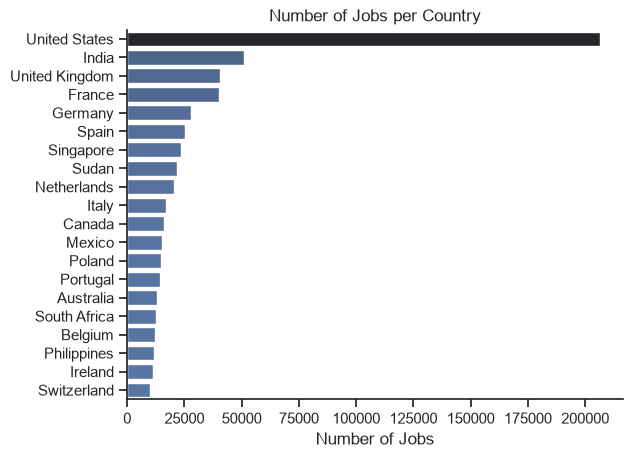

In [21]:

df_plot = df['job_country'].value_counts().head(20).rename_axis('job_country').reset_index(name='count')

sns.set_theme(style='ticks')
sns.barplot(data=df_plot, x='count', y='job_country', hue='count', palette='dark:b_r', legend=False)
sns.despine()
plt.title('Number of Jobs per Country')
plt.xlabel('Number of Jobs')
plt.ylabel('')
plt.show()

# Companies to Explore

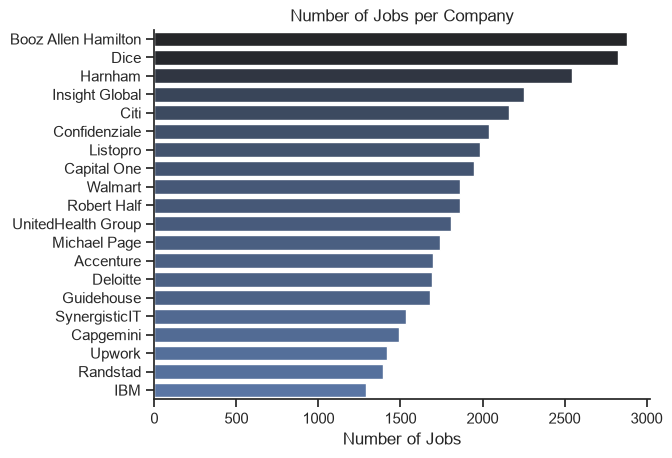

In [4]:
df_plot = df['company_name'].value_counts().to_frame()[1:].head(20)

sns.set_theme(style='ticks')
sns.barplot(data=df_plot, x='count', y='company_name', hue='count', palette='dark:b_r', legend=False)
sns.despine()
plt.title('Number of Jobs per Company')
plt.xlabel('Number of Jobs')
plt.ylabel('')
plt.show()

# Job Opportunities

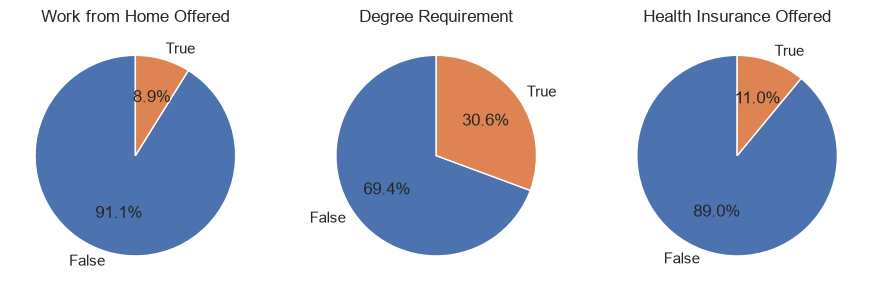

In [5]:
dict_column = {
    'job_work_from_home': 'Work from Home Offered',
    'job_no_degree_mention': 'Degree Requirement',
    'job_health_insurance': 'Health Insurance Offered'
}

fig, ax = plt.subplots(1, 3, figsize=(11, 3.5))

for i, (column, title) in enumerate(dict_column.items()):
    ax[i].pie(df[column].value_counts(), labels=['False', 'True'], autopct='%1.1f%%', startangle=90)
    ax[i].set_title(title)

plt.show()

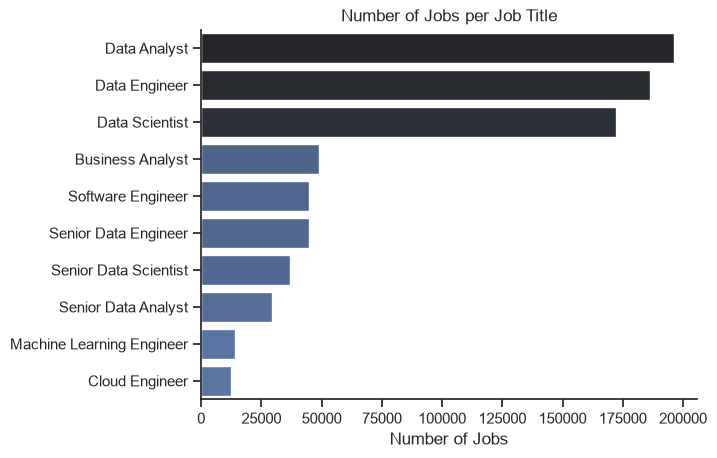

In [16]:
df_plot = df['job_title_short'].value_counts().to_frame()

sns.set_theme(style='ticks')
sns.barplot(data=df_plot, x='count', y='job_title_short', hue='count', palette='dark:b_r', legend=False)
sns.despine()
plt.title('Number of Jobs per Job Title')
plt.xlabel('Number of Jobs')
plt.ylabel('')
plt.show()

# Exploratory Data Analysis for Data Engineers vs Data Analysts in the US

In [7]:
df_de_us = df[(df['job_country'] == 'United States') & (df['job_title_short'] == 'Data Engineer')]
df_da_us = df[(df['job_country'] == 'United States') & (df['job_title_short'] == 'Data Analyst')]


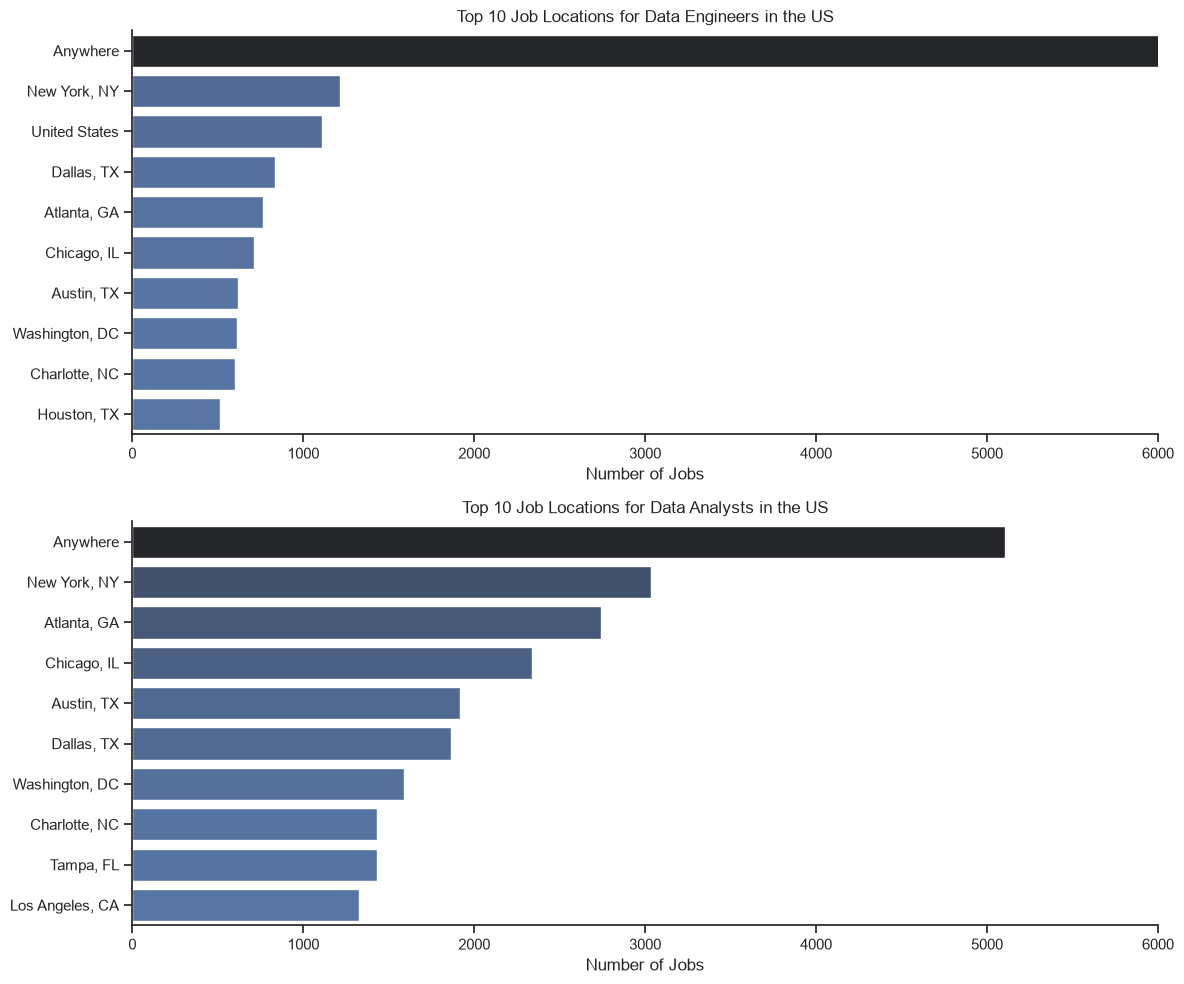

In [8]:
fig, ax = plt.subplots(2, 1, figsize=(12, 10))
sns.set_theme(style='ticks')

df_plot_de = (
    df_de_us['job_location']
    .value_counts()
    .head(10)
    .rename_axis('job_location')
    .reset_index(name='count')
)

sns.barplot(
    data=df_plot_de,
    x='count',
    y='job_location',
    hue='count',
    palette='dark:b_r',
    legend=False,
    ax=ax[0]
)

ax[0].set_title('Top 10 Job Locations for Data Engineers in the US')
ax[0].set_xlabel('Number of Jobs')
ax[0].set_ylabel('')
ax[0].set_xlim(0, 6000)

df_plot_da = (
    df_da_us['job_location']
    .value_counts()
    .head(10)
    .rename_axis('job_location')
    .reset_index(name='count')
)

sns.barplot(
    data=df_plot_da,
    x='count',
    y='job_location',
    hue='count',
    palette='dark:b_r',
    legend=False,
    ax=ax[1]
)

ax[1].set_title('Top 10 Job Locations for Data Analysts in the US')
ax[1].set_xlabel('Number of Jobs')
ax[1].set_ylabel('')
ax[1].set_xlim(0, 6000)

sns.despine()
plt.tight_layout()
plt.show()


## Job Opportunities

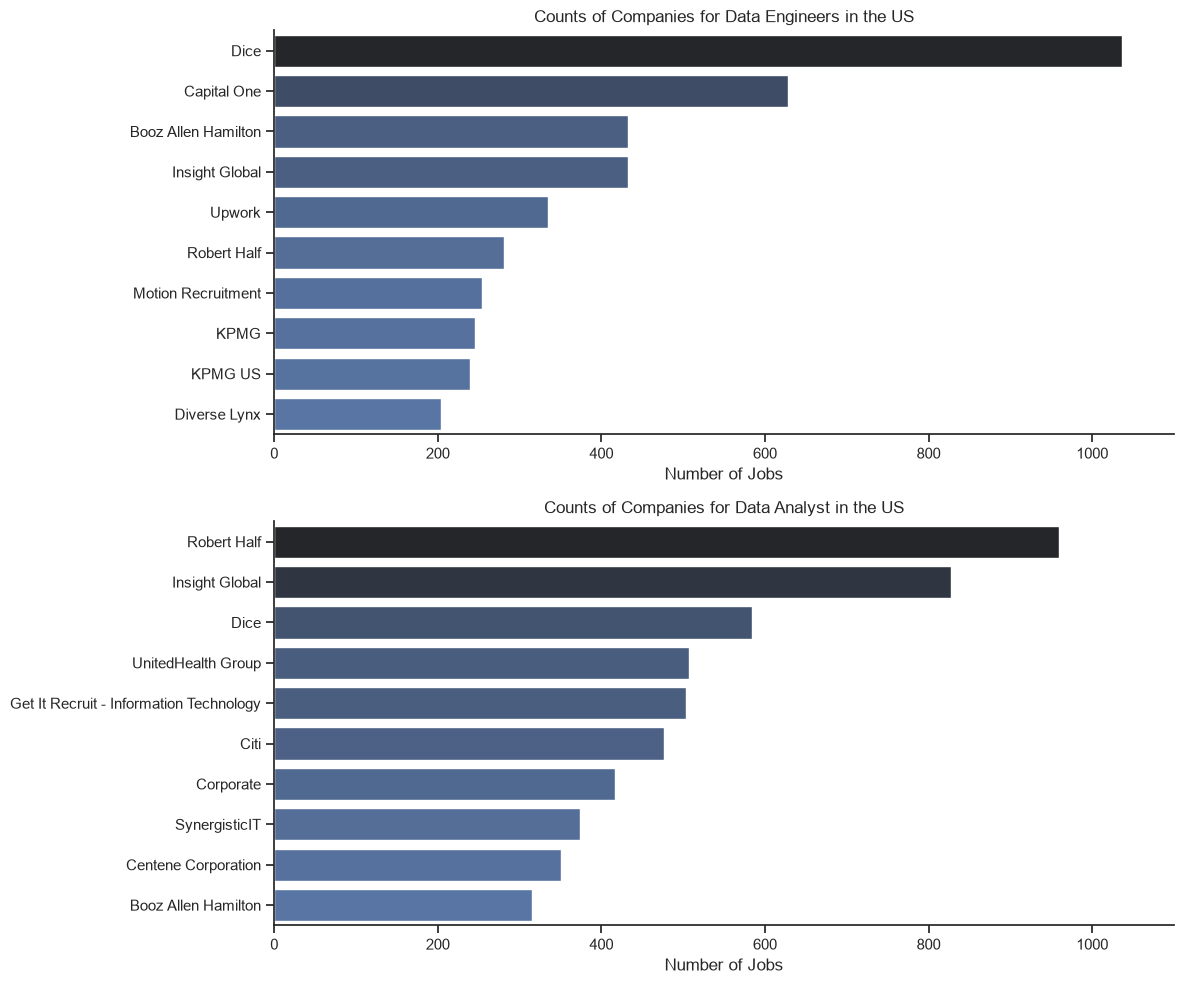

In [9]:
fig, ax = plt.subplots(2, 1, figsize=(12, 10))
sns.set_theme(style='ticks')

df_plot_de = (
    df_de_us['company_name']
    .value_counts()
    .head(10)
    .rename_axis('company_name')
    .reset_index(name='count')
)

sns.barplot(
    data=df_plot_de,
    x='count',
    y='company_name',
    hue='count',
    palette='dark:b_r',
    legend=False,
    ax=ax[0]
)

ax[0].set_title('Counts of Companies for Data Engineers in the US')
ax[0].set_xlabel('Number of Jobs')
ax[0].set_ylabel('')
ax[0].set_xlim(0, 1100)

df_plot_da = (
    df_da_us['company_name']
    .value_counts()
    .head(10)
    .rename_axis('company_name')
    .reset_index(name='count')
)

sns.barplot(
    data=df_plot_da,
    x='count',
    y='company_name',
    hue='count',
    palette='dark:b_r',
    legend=False,
    ax=ax[1]
)

ax[1].set_title('Counts of Companies for Data Analyst in the US')
ax[1].set_xlabel('Number of Jobs')
ax[1].set_ylabel('')
ax[1].set_xlim(0, 1100)

sns.despine()
plt.tight_layout()
plt.show()


# Data Engineers vs Data Analysts Job Opportunities

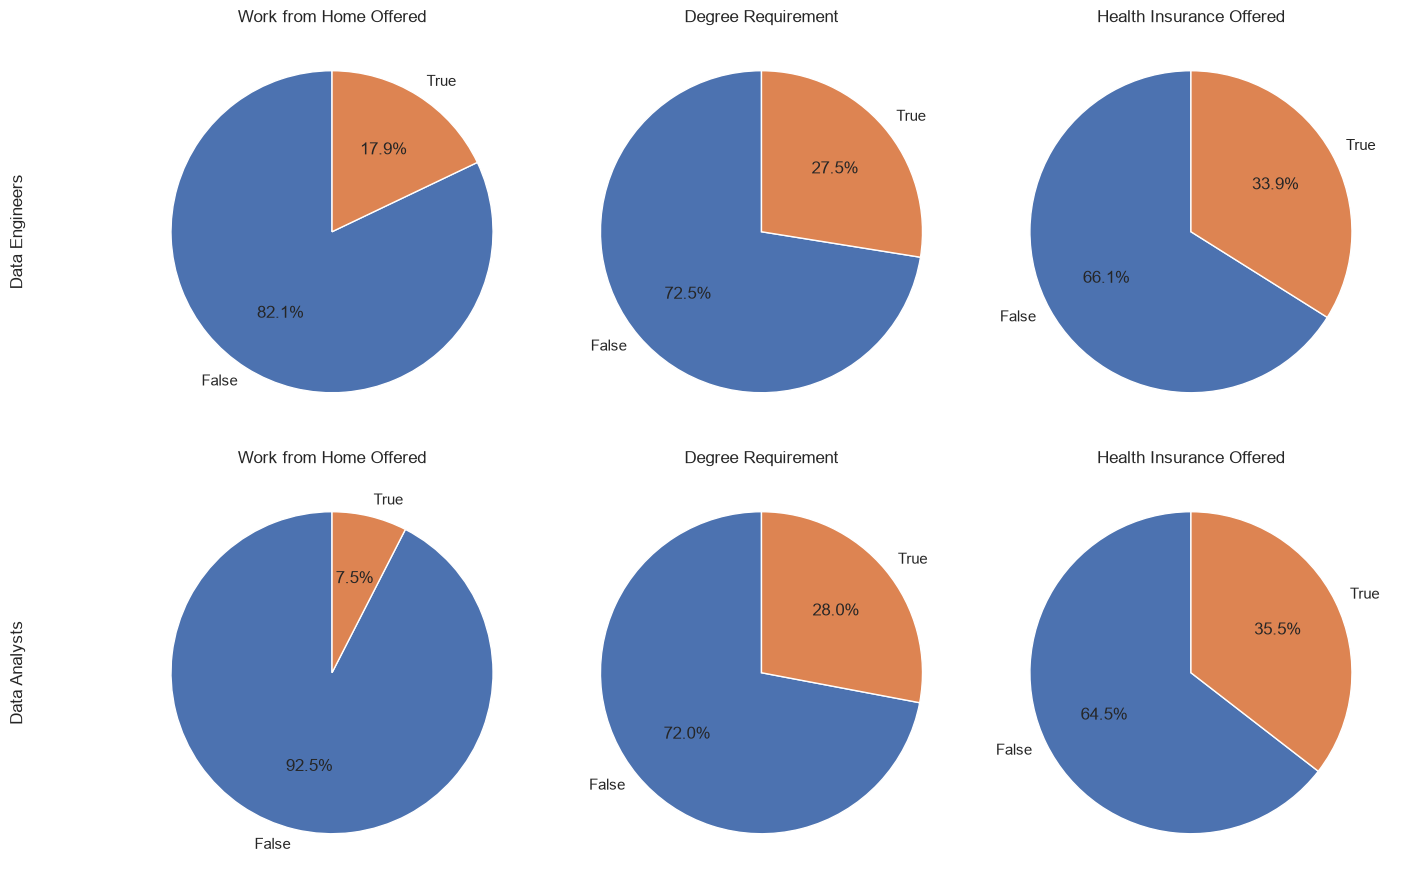

In [11]:

dict_column = {
    'job_work_from_home': 'Work from Home Offered',
    'job_no_degree_mention': 'Degree Requirement',
    'job_health_insurance': 'Health Insurance Offered'
}

fig, ax = plt.subplots(2, 3, figsize=(14, 9))

datasets = [df_de_us, df_da_us]
roles = ['Data Engineers', 'Data Analysts']

for row, (df_role, role) in enumerate(zip(datasets, roles)):
    for col, (column, title) in enumerate(dict_column.items()):
        counts = df_role[column].value_counts().reindex([False, True], fill_value=0)

        ax[row, col].pie(
            counts,
            labels=['False', 'True'],
            autopct='%1.1f%%',
            startangle=90
        )

        ax[row, col].set_title(title)

    ax[row, 0].text(
        -0.3, 0.5, role,
        transform=ax[row, 0].transAxes,
        rotation=90,
        va='center',
        fontsize=12
    )

plt.tight_layout()
plt.show()
